# General Data Science Track — Session 06
## Patient trajectories and mixed-effects models
**MED-EL research preparation · Estimated core time: 60 minutes**

## Why this matters
Research question: **“How does the mean diagonal telemetry proxy vary over follow-up, after accounting for measurement protocol and stable differences between patients?”** You already know mixed models in R; the goal is to recover that workflow in Python and make the hierarchy visible in the figures. Compare a pooled fit with a patient random-intercept model and explain what changes.

## Learning objectives
- Plot individual trajectories without connecting different patients.
- Audit visit coverage and the relationship between protocol and time.
- Fit and inspect a random-intercept model using statsmodels.
- Distinguish population mean predictions from patient-specific fitted values.
- Report uncertainty, convergence, and limitations of an incomplete follow-up panel.

## R-to-Python bridge
| R / lme4 | Python / statsmodels |
|---|---|
| `lmer(y ~ time + group + (1 | id), data=d)` | `smf.mixedlm("y ~ time + C(group)", d, groups=d["id"], re_formula="1").fit()` |
| `fixef(fit)` | `fit.fe_params` |
| `VarCorr(fit)` | `fit.cov_re` and `fit.scale` |
| patient-conditional `fitted(fit)` | `fit.fittedvalues` |
| fixed-effects-only prediction | `fit.predict(new_data)` |

`MixedLM` has a fixed-effects formula, a grouping argument, and an optional random-effects formula. For these exercises, one implant per patient makes the patient the grouping unit.

## Suggested pacing
Tasks 1–3: 18 min · Tasks 4–6: 22 min · Tasks 7–8: 12 min · Retrieval/reasoning/reflection: 8 min.

## Inputs and analysis contract
Start Jupyter from the repository root and select **Python (learning-python)** (`.venv`). All files already exist in `data/ci_telemetry/`; no downloads or prior notebook variables are needed. Read [the data dictionary](data/ci_telemetry/README.md) when a field is unfamiliar.

**All data are synthetic.** There are 96 patients with exactly one implant each, 360 observed visits, and 144 directed cell records per visit. Matrix rows stimulate; columns record. Contacts 1–12 have an index order but no claimed anatomical direction. These are teaching conventions, not a description of MED-EL's internal export. `voltage_mv / stim_current_ua` gives a synthetic V/I proxy in kΩ; it is not automatically the manufacturer's clinical impedance measurement. Preserve the original tables. Write short explanations in new markdown cells or print them. Exercise cells are intentionally empty.

Load `visit_features.csv` independently. Use all observed visits. Model `diag_mean_kohm` with actual `months_since_implant`, centered age, categorical array type, and categorical protocol. Select complete cases explicitly and use the same sample for every core model. Six patients lack age, so expect 90 patients in the modeling sample; compute the remaining visit count rather than assuming 90×4. Missing month-6 visits remain absent.

In [1]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf
from plotnine import *

## Task 1 — Count people, visits, and follow-up (5 min)
Load `features`; inspect visits per patient and patient counts per scheduled window. Predict why the overall count is below 96×4 before inspecting the table.

Acceptance: 96 patients, 360 unique visits; scheduled-window counts 96, 96, 96, and 72 at months 0, 1, 3, and 6. Create `model_data` with complete outcome, actual time, age, array, and protocol; center age at 50. Check nonmissing patient IDs and 90 unique patients.

Methods: `.groupby(...).size()`, `.nunique()`, `.dropna(subset=[...])`, `.copy()`. Explain why a missing follow-up visit does not represent zero impedance.

In [2]:
features = pd.read_csv("data/ci_telemetry/visit_features.csv")
print(features.dtypes)
print(features.shape)

visit_id                    str
patient_id                  str
implant_id                  str
visit_month               int64
days_since_implant        int64
visit_date                  str
protocol                    str
stim_current_ua         float64
diag_mean_kohm          float64
diag_sd_kohm            float64
n_diag_valid              int64
near_mean_kohm          float64
far_mean_kohm           float64
age_at_implant_years    float64
array_type                  str
site                        str
implant_side                str
months_since_implant    float64
dtype: object
(360, 18)


In [3]:
features["visit_id"].nunique()

360

In [4]:
features.groupby("patient_id").size()

patient_id
CI001    4
CI002    3
CI003    4
CI004    4
CI005    3
        ..
CI092    3
CI093    4
CI094    4
CI095    4
CI096    4
Length: 96, dtype: int64

There are 96 Patients but not all of them went 4 times. 

In [5]:
features.groupby("visit_month").size()

visit_month
0    96
1    96
3    96
6    72
dtype: int64

In [24]:
features["age_centered"] = features["age_at_implant_years"] - 50
model_data = features[["patient_id", "diag_mean_kohm", "months_since_implant", "age_at_implant_years", "array_type", "protocol", "visit_month"]].dropna()
model_data = model_data.dropna()

## Task 2 — Individual trajectories and a population summary (7 min)
Draw trajectories for the first 12 sorted patient IDs from `model_data`, using actual months on x, diagonal mean on y, and patient ID as the line group. Show points colored by protocol. Keep a fixed patient selection so the plot is reproducible.

Then plot the mean by scheduled visit window for **all** patients in `model_data`, with the number of patients contributing at each window in a separate table. Explain why a changing average can combine within-patient change and changing sample composition.

Plotnine hint: use `aes(group="patient_id")` for lines; put `aes(color="protocol")` on the point layer so a protocol change does not split a patient's line into separate color groups. Sort by patient and actual time first.

In [19]:
# select the first 12 unique patients
first12_ids = sorted(model_data["patient_id"].unique())[:12]

first12_data = model_data[model_data["patient_id"].isin(first12_ids)]
first12_data = first12_data.sort_values(["patient_id", "months_since_implant"])

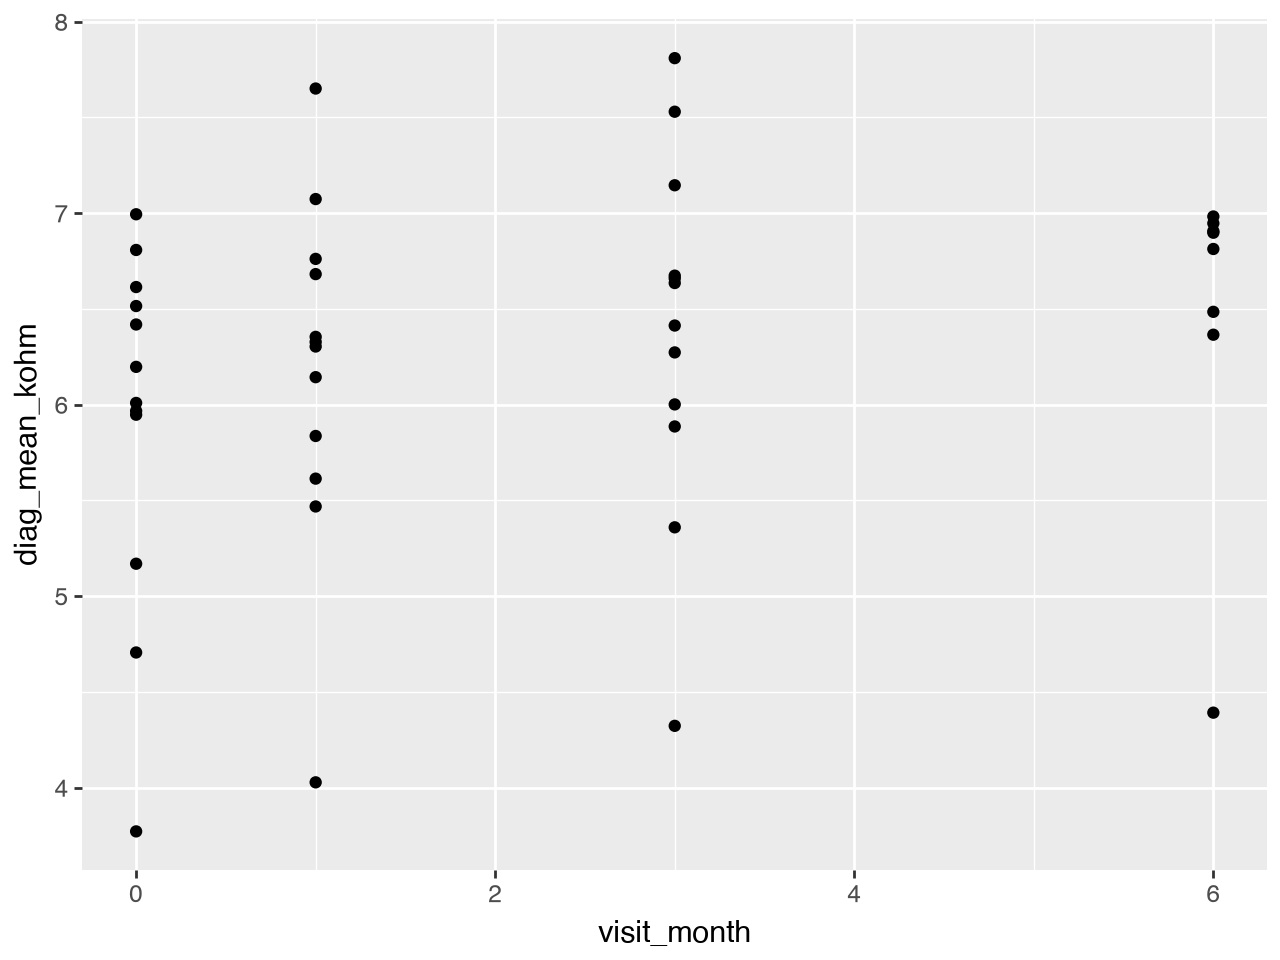

In [20]:
(
    ggplot(first12_data, aes(x="visit_month", y="diag_mean_kohm"))
    + geom_point()
)

In [21]:
count_table = first12_data.groupby("visit_month").agg(
    patient_count=("patient_id", "nunique")
).reset_index()
count_table

,visit_month,patient_count
0,0,12
1,1,12
2,3,12
3,6,8


## Task 3 — Is time entangled with measurement settings? (6 min)
Cross-tabulate scheduled visit window and protocol, using both counts and row proportions. Make a point/boxplot of diagonal mean by scheduled window, separated by protocol.

Methods: `pd.crosstab(..., normalize="index")`, plotnine `facet_wrap`. Confirm that both protocols appear at every scheduled window in the analysis sample.

Explain why a protocol offset can resemble biological change when one protocol is used more often later. Why would perfect alignment between protocol and visit time make their separate effects hard or impossible to identify?

In [22]:
pd.crosstab(model_data["visit_month"], model_data["protocol"]).reset_index()

protocol,visit_month,v1,v2
0,0,72,18
1,1,61,29
2,3,36,54
3,6,12,56


In [34]:
model_data["visit_month"] = model_data["visit_month"].astype(str)
model_data = model_data.dropna()

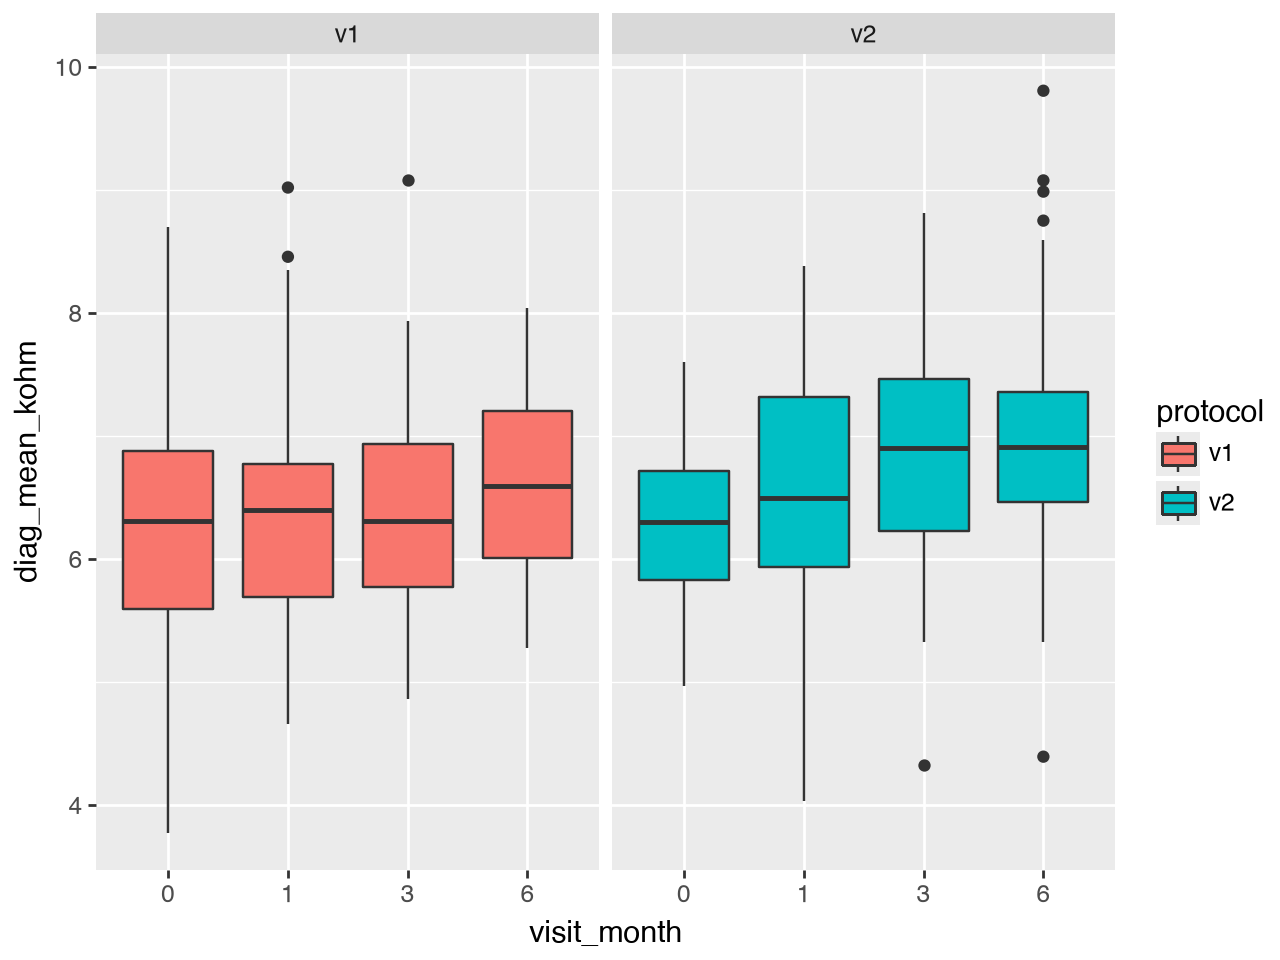

In [36]:
(
    ggplot(model_data, aes(x="visit_month", y="diag_mean_kohm", fill="protocol")) +
    geom_boxplot() +
    facet_wrap("~protocol")
)

## Task 4 — Fit a pooled model as a comparison (5 min)
Fit `pooled` by OLS on `model_data`, with actual months, centered age, array, and protocol. Retain the estimated time slope and its confidence interval.

Unrelated example:
```python
pooled_example = smf.ols("weight ~ week + C(feed)", data=animals, missing="raise").fit()
```
State the independence assumption this ordinary covariance estimate uses and why it is questionable here. This is a comparison model; do not treat its p-value as the final inference.

In [43]:
model_data["age_centered"] = model_data["age_at_implant_years"] - 50

In [45]:
pooled = smf.ols(data = model_data, 
                 formula="diag_mean_kohm ~ months_since_implant + age_centered + array_type + protocol",
                 missing = "raise").fit()

pooled.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:         diag_mean_kohm   R-squared:                       0.273
Model:                            OLS   Adj. R-squared:                  0.265
Method:                 Least Squares   F-statistic:                     31.32
Date:                Mon, 28 Sep 2026   Prob (F-statistic):           3.78e-22
Time:                        14:20:59   Log-Likelihood:                -421.25
No. Observations:                 338   AIC:                             852.5
Df Residuals:                     333   BIC:                             871.6
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
=========================================================================================
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                 5.9542      0.086     69.106      0.000       5.785       6.124
array_type[T.array_B]     0.3569      0.093      3.850      0.000       0.175       0.539
protocol[T.v2]            0.2135      0.105      2.043      0.042       0.008       0.419
months_since_implant      0.0875      0.024      3.649      0.000       0.040       0.135
age_centered              0.0276      0.003      9.102      0.000       0.022       0.034
==============================================================================
Omnibus:                        4.046   Durbin-Watson:                   0.535
Prob(Omnibus):                  0.132   Jarque-Bera (JB):                4.107
Skew:                           0.265   Prob(JB):                        0.128
Kurtosis:                       2.893   Cond. No.                         40.2
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [ ]:
pooled.conf_int()

,0,1
Intercept,5.784674,6.123647
array_type[T.array_B],0.174565,0.539300
protocol[T.v2],0.007887,0.419149
months_since_implant,0.040317,0.134631
age_centered,0.021645,0.033580


In [57]:
pd.concat([pooled.params.to_frame(name="Estimate"), 
           pooled.conf_int()], 
           axis=1).rename(columns={0: "CI Lower", 1: "CI Upper"})

,Estimate,CI Lower,CI Upper
Intercept,5.954160,5.784674,6.123647
array_type[T.array_B],0.356933,0.174565,0.539300
protocol[T.v2],0.213518,0.007887,0.419149
months_since_implant,0.087474,0.040317,0.134631
age_centered,0.027613,0.021645,0.033580


## Task 5 — Fit a patient random-intercept model (9 min)
Fit `mixed` using the same fixed-effects formula as `pooled`, with `groups=model_data["patient_id"]`, `re_formula="1"`, and `.fit(reml=True, method="lbfgs")`. Inspect `.summary()` and `.converged`, and retain any warnings.

Unrelated example:
```python
model = smf.mixedlm("weight ~ week + C(feed)", data=animals,
                    groups=animals["animal_id"], re_formula="1")
result = model.fit(reml=True, method="lbfgs")
```
Acceptance: the model uses the same rows as `pooled`, converges, and has a finite positive residual variance. Extract `.fe_params`, `.cov_re`, and `.scale`; explain their different roles.

If fitting warns or fails, first check missing values, groups, variation within groups, and redundant predictors. Record the issue rather than silently suppressing warnings. `method="powell"` is a possible numerical cross-check after checking the specification, not a cure for an unidentified model.

In [63]:
mixed = smf.mixedlm(data=model_data,
                    formula="diag_mean_kohm ~ months_since_implant + age_centered + array_type + protocol",
                    groups=model_data["patient_id"],
                    re_formula="1",
                    missing="raise").fit(reml=True, method="lbfgs")

mixed.summary()

<class 'statsmodels.iolib.summary2.Summary'>
"""
             Mixed Linear Model Regression Results
===============================================================
Model:             MixedLM  Dependent Variable:  diag_mean_kohm
No. Observations:  338      Method:              REML          
No. Groups:        90       Scale:               0.0312        
Min. group size:   3        Log-Likelihood:      -104.9396     
Max. group size:   4        Converged:           Yes           
Mean group size:   3.8                                         
---------------------------------------------------------------
                      Coef. Std.Err.   z    P>|z| [0.025 0.975]
---------------------------------------------------------------
Intercept             5.947    0.132 45.068 0.000  5.688  6.206
array_type[T.array_B] 0.341    0.179  1.902 0.057 -0.010  0.692
protocol[T.v2]        0.259    0.026  9.949 0.000  0.208  0.310
months_since_implant  0.089    0.005 16.676 0.000  0.079  0.100
age_centered          0.027    0.006  4.644 0.000  0.016  0.039
Group Var             0.704    0.711                           
===============================================================

"""

In [67]:
mixed.cov_re

,Group
Group,0.703968


In [66]:
mixed.fe_params

Intercept                5.947058
array_type[T.array_B]    0.340616
protocol[T.v2]           0.259062
months_since_implant     0.089151
age_centered             0.027292
dtype: float64

In [65]:
mixed.converged

True

## Task 6 — Compare effects and quantify clustering (8 min)
Create a small table comparing the time slope and its 95% interval from `pooled` and `mixed`. Do not expect a prescribed ordering of interval widths. Restrict mixed-model coefficient reporting to `.fe_params.index`; variance parameters are not fixed effects.

Calculate the random-intercept variance from `mixed.cov_re.iloc[0, 0]`, residual variance from `mixed.scale`, and the conditional ICC as random-intercept variance / (random-intercept variance + residual variance). Verify it lies between 0 and 1.

Explain the ICC as residual similarity of measurements from the same patient under this model, conditional on fixed effects. A random intercept allows different patient baselines but imposes a common time slope and a simple residual covariance structure.

## Task 7 — Predictions and residuals at the right level (7 min)
Create a small time grid from 0 to 6 months at age 50, `array_type="array_A"`, and `protocol="v1"`. Use `mixed.predict(grid)` and plot the population mean trajectory. Include all fixed-effect columns with their exact names.

For observed patients, compare `mixed.predict(model_data)` with `mixed.fittedvalues` and describe the role of each patient's estimated random intercept. Plot conditional residuals `mixed.resid` against actual time and inspect a Q–Q plot.

Acceptance: the grid prediction has one value per grid row; observed fitted values have one value per modeling row. Population predictions do not include a new patient's unknown random intercept. Do not use an OLS prediction-interval recipe as if it automatically supplied mixed-model predictive uncertainty.

## Task 8 — Write the longitudinal result (5 min)
Report patient and visit counts, the estimated per-month association with its interval, the ICC, convergence status, and one limitation revealed by the plots or sample construction.

Explain why protocol adjustment matters. Distinguish the fixture's known administrative follow-up truncation from a real study in which dropout might depend on patient condition. Neither a mixed model nor a small p-value fixes informative missingness by itself.

## Retrieval practice
From `model_data`, select patients with both month-0 and month-3 measurements. Pivot their diagonal means to one row per patient, calculate month-3 minus baseline, and report the mean and median change. Validate one row per patient. Explain why this paired contrast is not exactly the adjusted model's per-month slope.

## Professional reasoning
1. What additional levels would you consider if some patients had two implants and several matrices per session?
2. What could a common-slope random-intercept model miss if patients change at different rates?
3. Why should fixed-effect formulas not be compared using REML likelihood values across different fixed-effect specifications?

## Self-check and reflection
Record confidence **1–5**, the hardest point, one operation you can now explain, what needs repetition, and whether the workload was too light / about right / too heavy.

Finish line: restart the kernel, run your cells in order, and write a short research conclusion with its limitations. Ask for review of your attempt.

## Optional extension — outside the core hour
**25–40 minutes:** Fit a random-intercept-plus-time-slope model using `re_formula="~months_since_implant"`; check convergence and the random-effects covariance, and compare trajectory interpretation. With few visits, a more complex covariance is not automatically better.

Alternatively, fit a categorical scheduled-time model to explore departure from a linear trend. If comparing likelihoods/AIC for different fixed effects, refit the competing models with `reml=False` on the exact same rows and discuss the comparison's assumptions. Keep discovery separate from confirmation.

Reference: [statsmodels mixed-model example](https://www.statsmodels.org/stable/examples/notebooks/generated/mixed_lm_example.html).